In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns',None)


import warnings
warnings.filterwarnings('ignore')



In [2]:
df_train= pd.read_csv('laptops_train.csv')
df_train

,Manufacturer,Model Name,Category,Screen Size,Screen,CPU,RAM,Storage,GPU,Operating System,Operating System Version,Weight,Price
0,Apple,MacBook Pro,Ultrabook,"13.3""",IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,NaN,1.37kg,11912523.48
1,Apple,Macbook Air,Ultrabook,"13.3""",1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,NaN,1.34kg,7993374.48
2,HP,250 G6,Notebook,"15.6""",Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,NaN,1.86kg,5112900.00
3,Apple,MacBook Pro,Ultrabook,"15.4""",IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,NaN,1.83kg,22563005.40
4,Apple,MacBook Pro,Ultrabook,"13.3""",IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,NaN,1.37kg,16037611.20
...,...,...,...,...,...,...,...,...,...,...,...,...,...
972,Dell,Alienware 17,Gaming,"17.3""",Full HD 1920x1080,Intel Core i7 6700HQ 2.6GHz,32GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1070,Windows,10,4.42kg,24897600.00
973,Toshiba,Tecra A40-C-1DF,Notebook,"14.0""",Full HD 1920x1080,Intel Core i5 6200U 2.3GHz,8GB,256GB SSD,Intel HD Graphics 520,Windows,10,1.95kg,10492560.00
974,Asus,Rog Strix,Gaming,"17.3""",Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1060,Windows,10,2.73kg,18227710.80
975,HP,Probook 450,Notebook,"15.6""",IPS Panel Full HD 1920x1080,Intel Core i5 7200U 2.70GHz,8GB,128GB SSD + 1TB HDD,Nvidia GeForce 930MX,Windows,10,2.04kg,8705268.00


In [3]:
df_test= pd.read_csv('laptops_test.csv')
df_test

,Manufacturer,Model Name,Category,Screen Size,Screen,CPU,RAM,Storage,GPU,Operating System,Operating System Version,Weight,Price
0,HP,15-bs053od (i7-7500U/6GB/1TB/W10),Notebook,"15.6""",1366x768,Intel Core i7 7500U 2.7GHz,6GB,1TB HDD,Intel HD Graphics 620,Windows,10,2.04kg,5148468.0
1,Asus,Rog GL753VE-DS74,Gaming,"17.3""",Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1050 Ti,Windows,10,2.99kg,15552108.0
2,Dell,Inspiron 7579,2 in 1 Convertible,"15.6""",IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 7500U 2.7GHz,12GB,512GB SSD,Intel HD Graphics 620,Windows,10,2.19kg,11550708.0
3,Toshiba,Portege Z30-C-1CV,Notebook,"13.3""",Full HD 1920x1080,Intel Core i5 6200U 2.3GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows,7,1.2kg,10625940.0
4,Lenovo,IdeaPad 320-15ABR,Notebook,"15.6""",Full HD 1920x1080,AMD A12-Series 9720P 3.6GHz,6GB,256GB SSD,AMD Radeon 530,Windows,10,2.2kg,4881708.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
320,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,"14.0""",IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows,10,1.8kg,5673096.0
321,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,"13.3""",IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows,10,1.3kg,13329108.0
322,Lenovo,IdeaPad 100S-14IBR,Notebook,"14.0""",1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows,10,1.5kg,2036268.0
323,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,"15.6""",1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows,10,2.19kg,6793488.0


# Data Processing- Part 1

In [4]:
# removing 'kg' from Weight colunm and '"' from Screen Size

df_train['Weight']=df_train['Weight'].str.strip('kg')
df_train['Screen Size']=df_train['Screen Size'].str.strip('"')
df_train.head()

,Manufacturer,Model Name,Category,Screen Size,Screen,CPU,RAM,Storage,GPU,Operating System,Operating System Version,Weight,Price
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,NaN,1.37,11912523.48
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,NaN,1.34,7993374.48
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,NaN,1.86,5112900.00
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,NaN,1.83,22563005.40
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,NaN,1.37,16037611.20


In [5]:
df_train.dtypes

Manufacturer                 object
Model Name                   object
Category                     object
Screen Size                  object
Screen                       object
CPU                          object
RAM                          object
 Storage                     object
GPU                          object
Operating System             object
Operating System Version     object
Weight                       object
Price                       float64
dtype: object

In [6]:
df_train['Weight']=df_train['Weight'].astype(float,errors='raise')
df_train['Screen Size']=df_train['Screen Size'].astype(float,errors='raise')

In [7]:
df_train.dtypes

Manufacturer                 object
Model Name                   object
Category                     object
Screen Size                 float64
Screen                       object
CPU                          object
RAM                          object
 Storage                     object
GPU                          object
Operating System             object
Operating System Version     object
Weight                      float64
Price                       float64
dtype: object

In [8]:
def fetch_processor(text):
    if 'Intel Core i5' in text:
        return 'Intel Core i5'
    elif 'Intel Core i7' in text:
        return 'Intel Core i7'
    elif 'Intel Core i3' in text:
        return 'Intel Core i3'
    elif text.startswith('Intel'):
        return 'Other Intel Processor'
    else:
        return 'AMD Processor'

In [9]:
df_train['CPU brand'] = df_train['CPU'].apply(fetch_processor)
df_train['CPU brand']

0      Intel Core i5
1      Intel Core i5
2      Intel Core i5
3      Intel Core i7
4      Intel Core i5
           ...      
972    Intel Core i7
973    Intel Core i5
974    Intel Core i7
975    Intel Core i5
976    Intel Core i5
Name: CPU brand, Length: 977, dtype: object

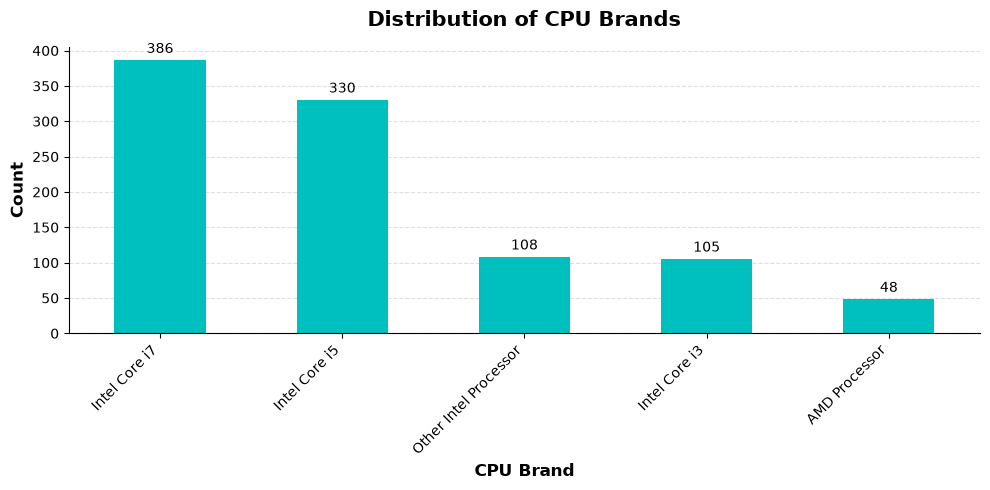

In [10]:
# plot box
plt.figure(figsize=(10,5))
ax=df_train['CPU brand'].value_counts().plot(kind='bar',color='c')

#labelling
ax.set_xlabel("CPU Brand", fontsize=12, fontweight='bold')
ax.set_ylabel("Count", fontsize=12, fontweight='bold')
ax.set_title("Distribution of CPU Brands", fontsize=15, fontweight='bold', pad=15)

# Rotate X-axis labels
plt.xticks(rotation=45, ha='right')

# Add count labels on bars
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)

# Add horizontal gridlines
ax.yaxis.grid(True, linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

# Remove top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [11]:
def gpu_type(text):
    if 'Intel' in text:
        return 'Intel'
    elif 'AMD' in text:
        return 'AMD'
    elif 'Nvidia' in text:
        return 'Nvidia'
    else:
        return 'Other GPU'

In [12]:
df_train['GPU Brand'] = df_train['GPU'].apply(gpu_type)
df_train['GPU Brand']

0       Intel
1       Intel
2       Intel
3         AMD
4       Intel
        ...  
972    Nvidia
973     Intel
974    Nvidia
975    Nvidia
976     Intel
Name: GPU Brand, Length: 977, dtype: object

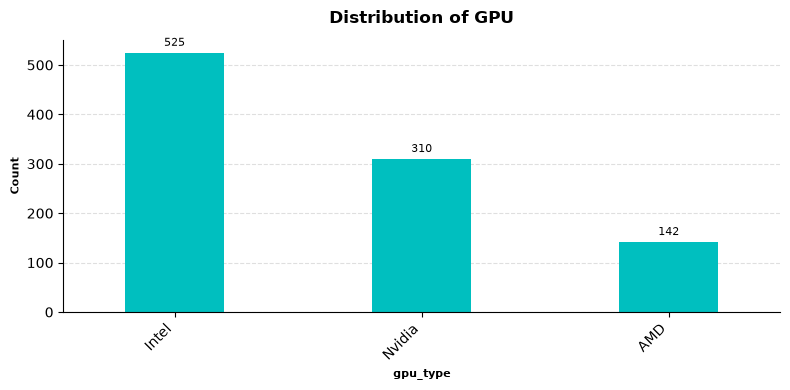

In [13]:
# plot box
plt.figure(figsize=(8,4))
ax=df_train['GPU Brand'].value_counts().plot(kind='bar',color='c',width=0.4)

#labelling
ax.set_xlabel("gpu_type", fontsize=8, fontweight='bold')
ax.set_ylabel("Count", fontsize=8, fontweight='bold')
ax.set_title("Distribution of GPU", fontsize=12, fontweight='bold', pad=12)

# Rotate X-axis labels
plt.xticks(rotation=45, ha='right')

# Add count labels on bars
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=8)

# Add horizontal gridlines
ax.yaxis.grid(True, linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

# Remove top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [14]:
df_train['Operating System'] = df_train['Operating System'].replace('Mac OS', 'macOS')

In [15]:
df_train['Screen Quality'] = df_train['Screen'].str.slice(-9)


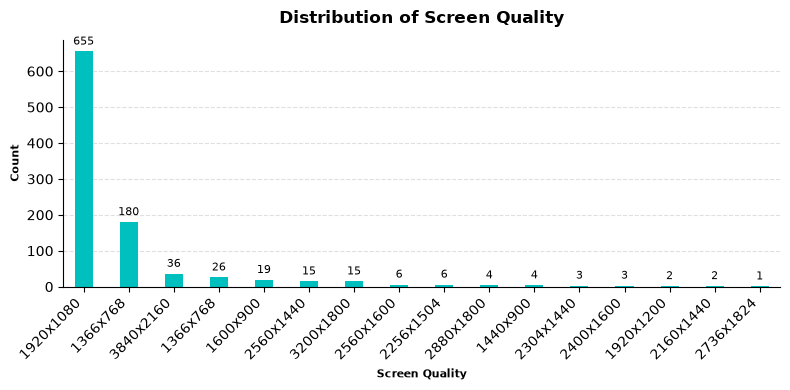

In [16]:
# bar plot
plt.figure(figsize=(8,4))
ax=df_train['Screen Quality'].value_counts().plot(kind='bar',color='c',width=0.4)

#labelling
ax.set_xlabel("Screen Quality", fontsize=8, fontweight='bold')
ax.set_ylabel("Count", fontsize=8, fontweight='bold')
ax.set_title("Distribution of Screen Quality", fontsize=12, fontweight='bold', pad=12)

# Rotate X-axis labels
plt.xticks(rotation=45, ha='right')

# Add count labels on bars
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=8)

# Add horizontal gridlines
ax.yaxis.grid(True, linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

# Remove top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [17]:
def fetch_storage(text):
    if '128GB SSD' in text:
        return '128GB SSD'
    elif '256GB SSD' in text:
        return '256GB SSD'
    elif '512GB SSD' in text:
        return '512GB SSD'
    elif '500GB HDD' in text:
        return '500GB HDD'
    elif '1TB HDD' in text:
        return '1TB HDD'
    elif 'Flash Storage' in text:
        return 'Flash Storage'
    else:
        return 'Mixed Storage'

In [18]:
df_train['Storage Type'] = df_train[' Storage'].apply(fetch_storage)

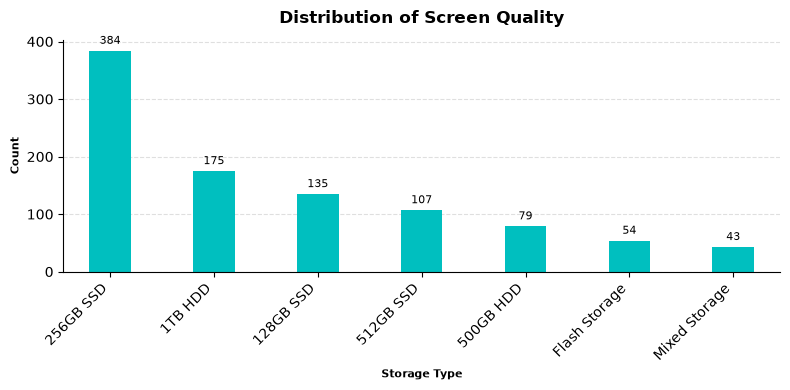

In [19]:
# bar plot
plt.figure(figsize=(8,4))
ax=df_train['Storage Type'].value_counts().plot(kind='bar',color='c',width=0.4)

#labelling
ax.set_xlabel("Storage Type", fontsize=8, fontweight='bold')
ax.set_ylabel("Count", fontsize=8, fontweight='bold')
ax.set_title("Distribution of Screen Quality", fontsize=12, fontweight='bold', pad=12)

# Rotate X-axis labels
plt.xticks(rotation=45, ha='right')

# Add count labels on bars
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=8)

# Add horizontal gridlines
ax.yaxis.grid(True, linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

# Remove top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# Exploratory Data Analysis

In [20]:
df_train.select_dtypes(include='object').nunique()

Manufacturer                 19
Model Name                  488
Category                      6
Screen                       38
CPU                         106
RAM                           8
 Storage                     36
GPU                          98
Operating System              6
Operating System Version      4
CPU brand                     5
GPU Brand                     3
Screen Quality               16
Storage Type                  7
dtype: int64

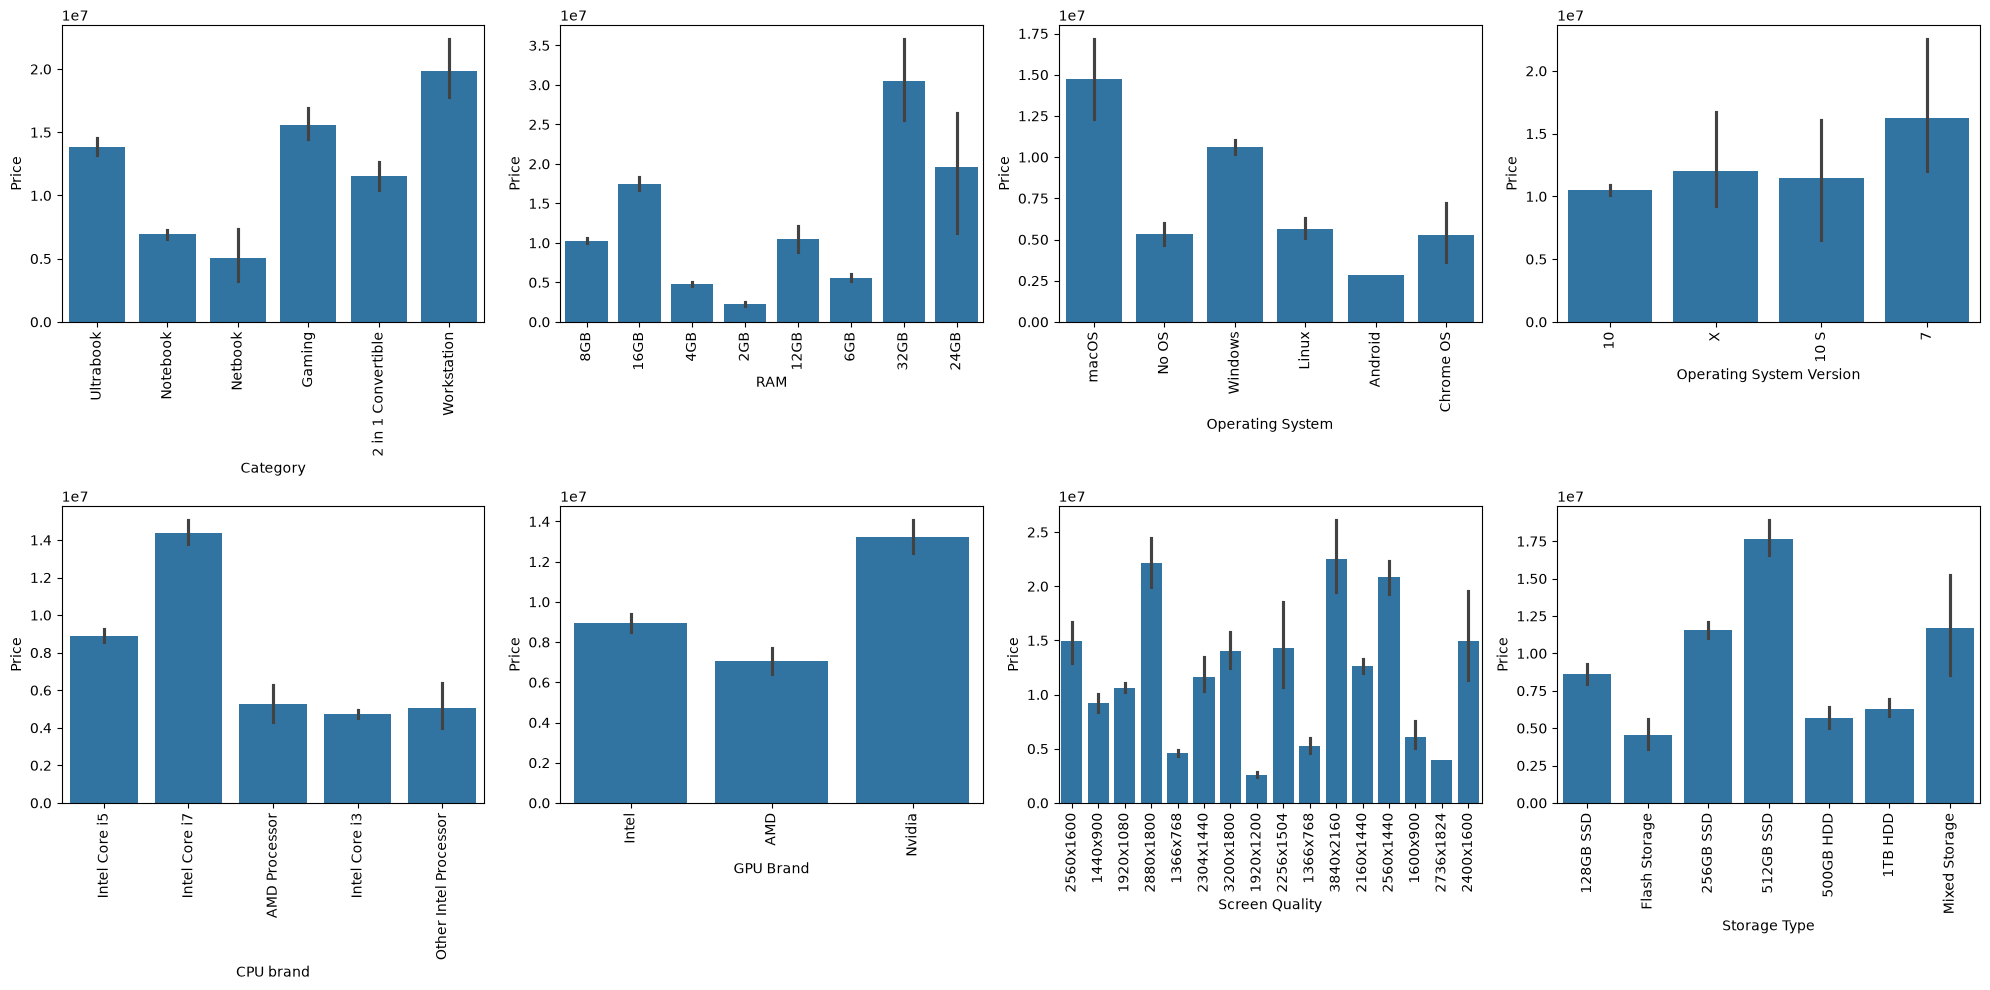

In [21]:
# list of categorical variables to plot
cat_vars = ['Category', 'RAM', 'Operating System', 'Operating System Version', 'CPU brand', 
            'GPU Brand', 'Screen Quality', 'Storage Type']

# create figure with subplots
fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))
axs = axs.flatten()

# create barplot for each categorical variable
for i,var in enumerate(cat_vars):
    sns.barplot(x=var, y='Price', data=df_train, ax=axs[i])
    axs[i].set_xticklabels(axs[i].get_xticklabels(), rotation=90)

# adjust spacing between subplots
fig.tight_layout()

# show plot
plt.show()

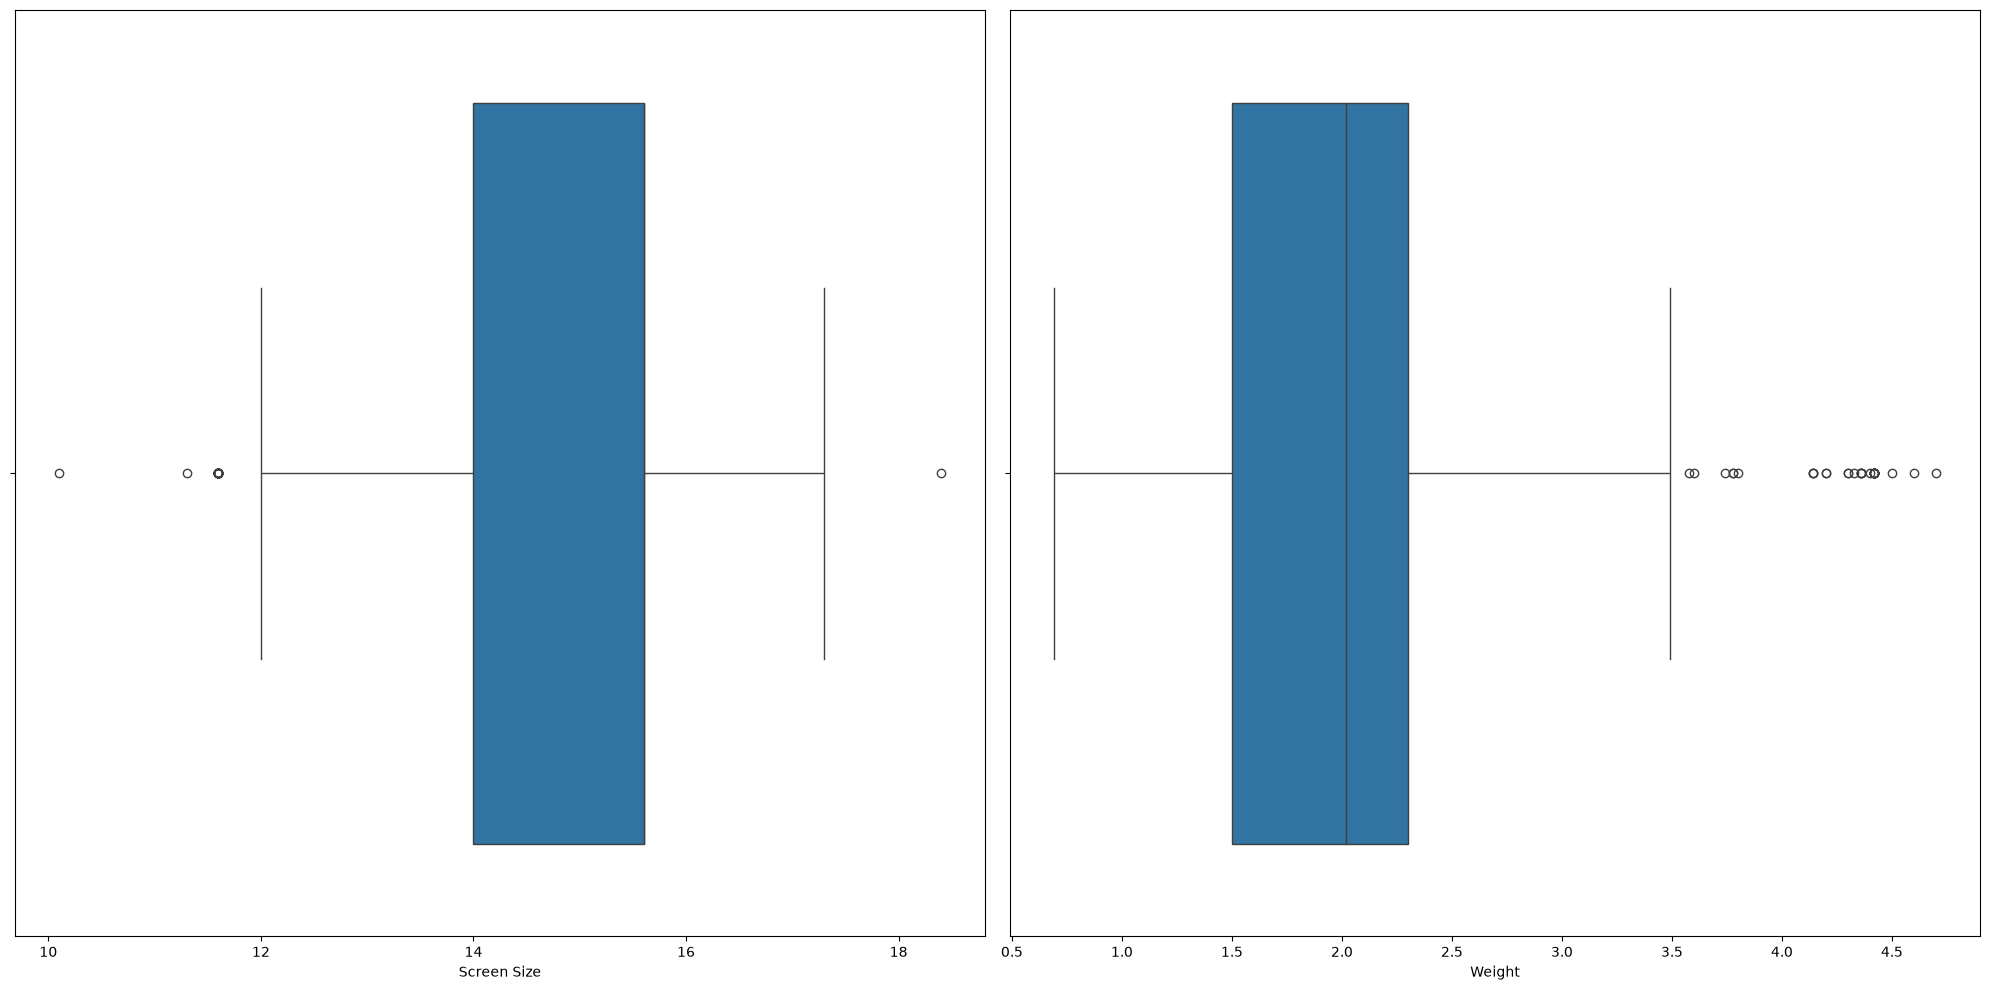

In [22]:
num_vars = ['Screen Size', 'Weight']

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(20, 10))
axs = axs.flatten()

for i, var in enumerate(num_vars):
    sns.boxplot(x=var, data=df_train, ax=axs[i])

fig.tight_layout()

plt.show()

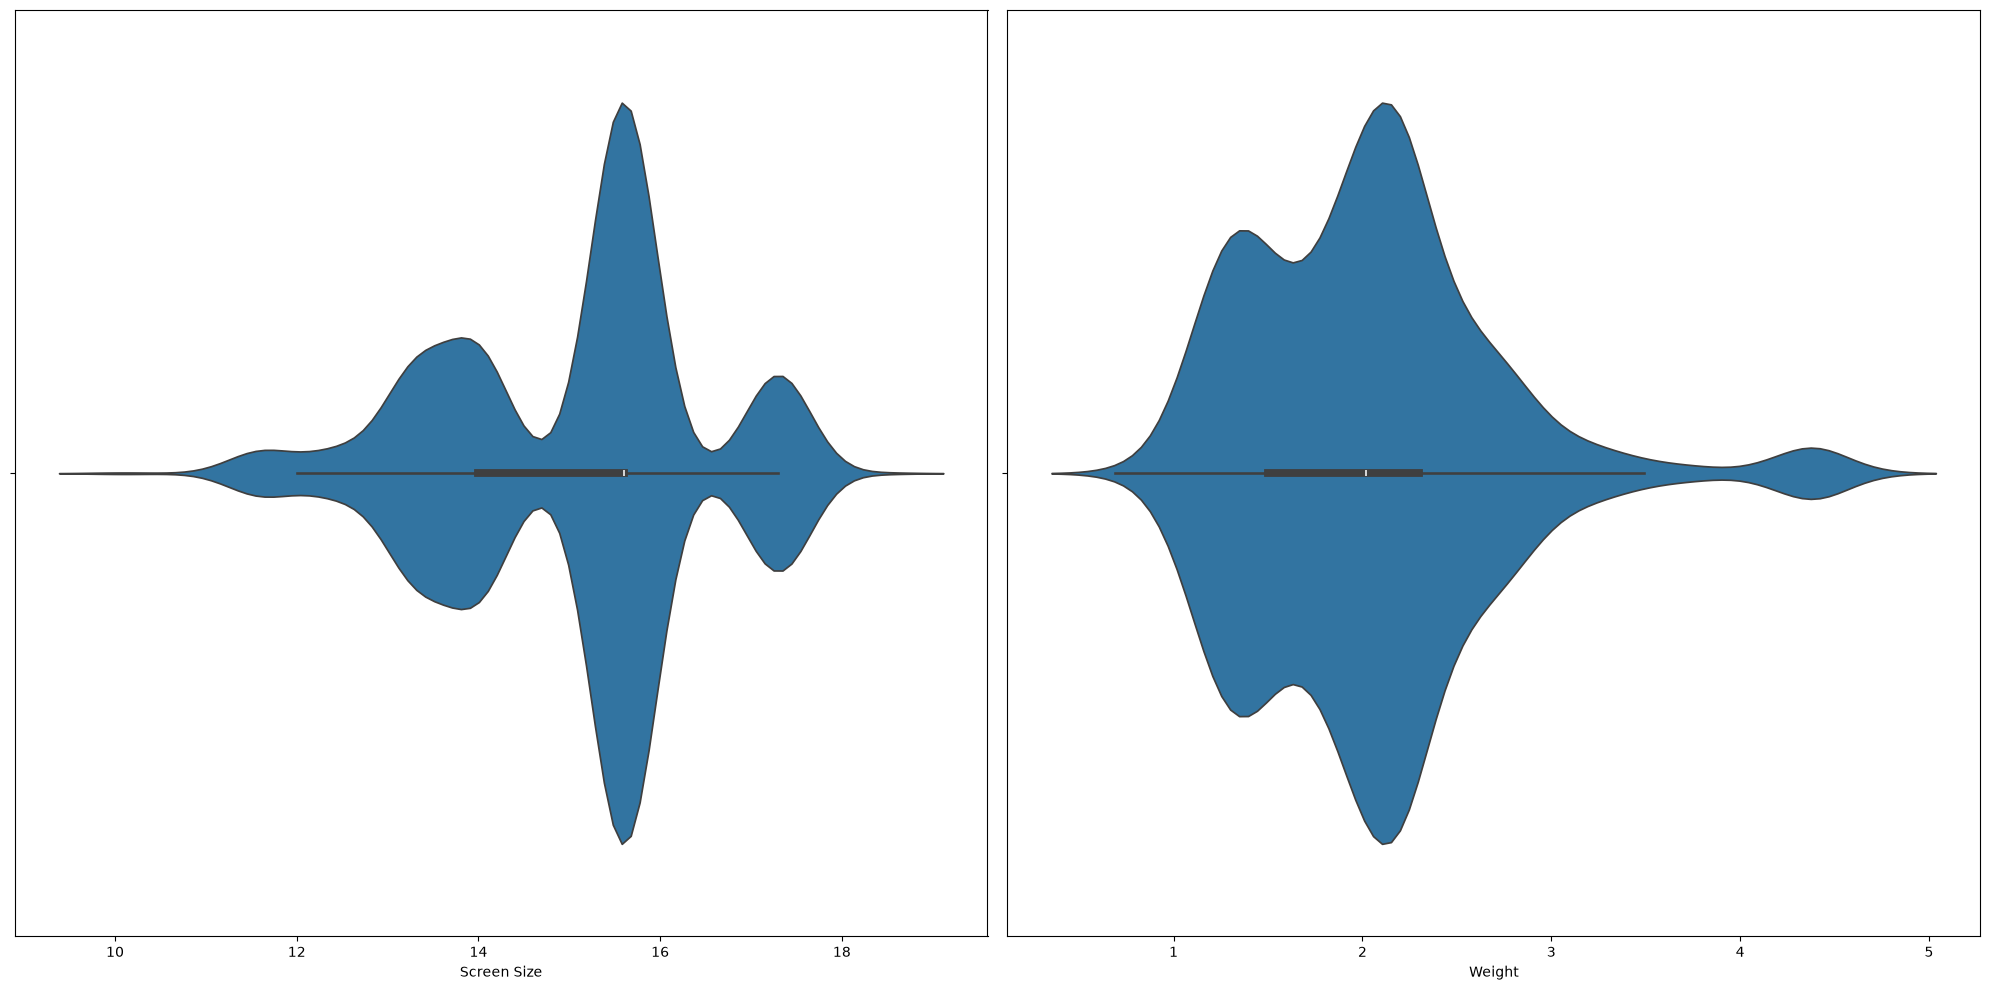

In [23]:
num_vars = ['Screen Size', 'Weight']

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(20, 10))
axs = axs.flatten()

for i, var in enumerate(num_vars):
    sns.violinplot(x=var, data=df_train, ax=axs[i])

fig.tight_layout()

plt.show()

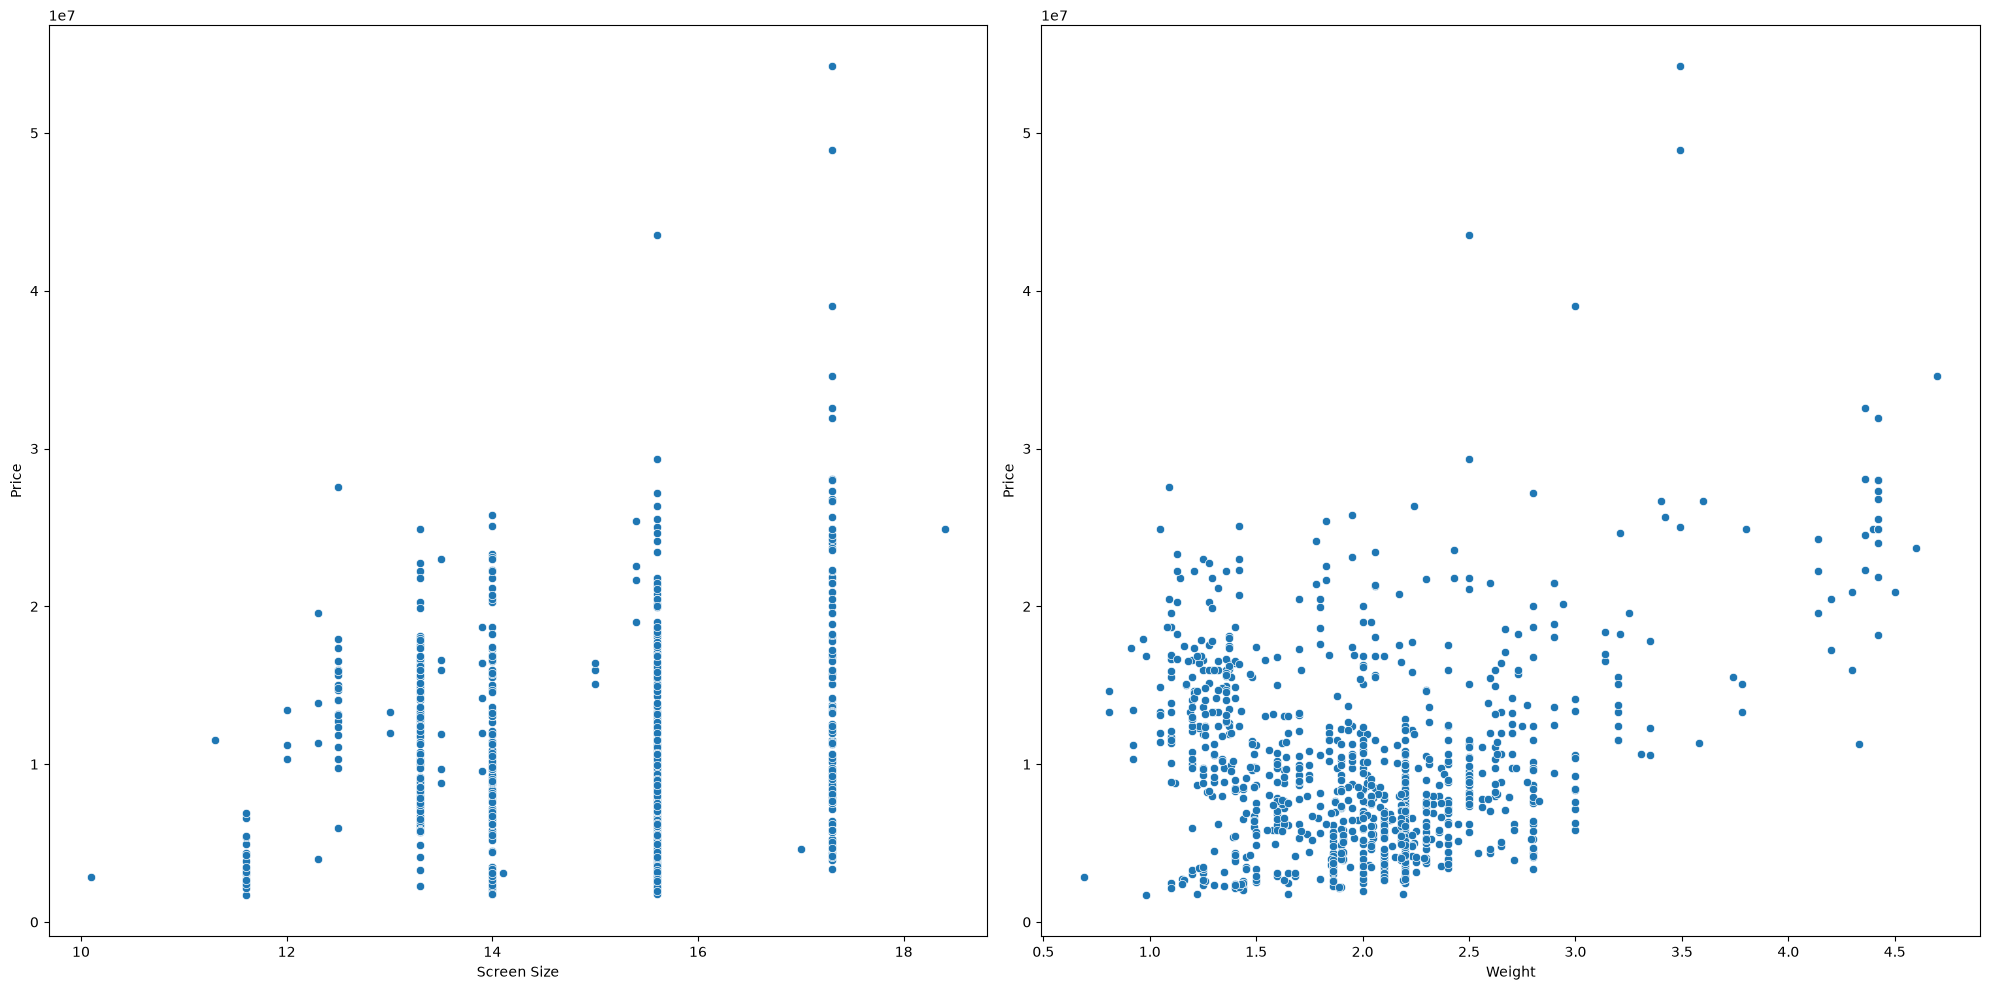

In [24]:
num_vars = ['Screen Size', 'Weight']

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(20, 10))
axs = axs.flatten()

for i, var in enumerate(num_vars):
    sns.scatterplot(x=var, y='Price', data=df_train, ax=axs[i])

fig.tight_layout()

plt.show()

# Data Preprocessing Part 2

In [25]:
df_train.drop(columns=['Model Name', 'Screen', 'CPU', ' Storage', 'GPU'], inplace=True)
df_train.shape

(977, 12)

In [26]:
df_train.head()

,Manufacturer,Category,Screen Size,RAM,Operating System,Operating System Version,Weight,Price,CPU brand,GPU Brand,Screen Quality,Storage Type
0,Apple,Ultrabook,13.3,8GB,macOS,NaN,1.37,11912523.48,Intel Core i5,Intel,2560x1600,128GB SSD
1,Apple,Ultrabook,13.3,8GB,macOS,NaN,1.34,7993374.48,Intel Core i5,Intel,1440x900,Flash Storage
2,HP,Notebook,15.6,8GB,No OS,NaN,1.86,5112900.00,Intel Core i5,Intel,1920x1080,256GB SSD
3,Apple,Ultrabook,15.4,16GB,macOS,NaN,1.83,22563005.40,Intel Core i7,AMD,2880x1800,512GB SSD
4,Apple,Ultrabook,13.3,8GB,macOS,NaN,1.37,16037611.20,Intel Core i5,Intel,2560x1600,256GB SSD


In [27]:
check_missing = df_train.isnull().sum() * 100 / df_train.shape[0]
check_missing[check_missing > 0].sort_values(ascending=False)

Operating System Version    13.920164
dtype: float64

In [28]:
df_train.fillna('Unknown', inplace=True)
df_train.head()

,Manufacturer,Category,Screen Size,RAM,Operating System,Operating System Version,Weight,Price,CPU brand,GPU Brand,Screen Quality,Storage Type
0,Apple,Ultrabook,13.3,8GB,macOS,Unknown,1.37,11912523.48,Intel Core i5,Intel,2560x1600,128GB SSD
1,Apple,Ultrabook,13.3,8GB,macOS,Unknown,1.34,7993374.48,Intel Core i5,Intel,1440x900,Flash Storage
2,HP,Notebook,15.6,8GB,No OS,Unknown,1.86,5112900.00,Intel Core i5,Intel,1920x1080,256GB SSD
3,Apple,Ultrabook,15.4,16GB,macOS,Unknown,1.83,22563005.40,Intel Core i7,AMD,2880x1800,512GB SSD
4,Apple,Ultrabook,13.3,8GB,macOS,Unknown,1.37,16037611.20,Intel Core i5,Intel,2560x1600,256GB SSD


In [29]:
# Loop over each column in the DataFrame where dtype is 'object' and get unique values
for col in df_train.select_dtypes(include=['object']).columns: 
    print(f'{col}:{df_train[col].unique()}')

Manufacturer:['Apple' 'HP' 'Acer' 'Asus' 'Dell' 'Lenovo' 'Chuwi' 'MSI' 'Microsoft'
 'Toshiba' 'Huawei' 'Xiaomi' 'Vero' 'Razer' 'Mediacom' 'Samsung' 'Google'
 'Fujitsu' 'LG']
Category:['Ultrabook' 'Notebook' 'Netbook' 'Gaming' '2 in 1 Convertible'
 'Workstation']
RAM:['8GB' '16GB' '4GB' '2GB' '12GB' '6GB' '32GB' '24GB']
Operating System:['macOS' 'No OS' 'Windows' 'Linux' 'Android' 'Chrome OS']
Operating System Version:['Unknown' '10' 'X' '10 S' '7']
CPU brand:['Intel Core i5' 'Intel Core i7' 'AMD Processor' 'Intel Core i3'
 'Other Intel Processor']
GPU Brand:['Intel' 'AMD' 'Nvidia']
Screen Quality:['2560x1600' '1440x900' '1920x1080' '2880x1800' '1366x768' '2304x1440'
 '3200x1800' '1920x1200' '2256x1504' ' 1366x768' '3840x2160' '2160x1440'
 '2560x1440' '1600x900' '2736x1824' '2400x1600']
Storage Type:['128GB SSD' 'Flash Storage' '256GB SSD' '512GB SSD' '500GB HDD' '1TB HDD'
 'Mixed Storage']


In [30]:
from sklearn.preprocessing import LabelEncoder

# Loop over each column in the DataFrame where dtype is 'object'
for col in df_train.select_dtypes(include=['object']).columns:
    
    # Initialize a LabelEncoder object
    label_encoder = LabelEncoder()
    
    # Fit the encoder to the unique values in the column
    label_encoder.fit(df_train[col].unique())
    
    # Transform the column using the encoder
    df_train[col] = label_encoder.transform(df_train[col])
    
    # Print the column name and the unique encoded values
    print(f"{col}: {df_train[col].unique()}")

Manufacturer: [ 1  7  0  2  4 10  3 11 13 16  8 18 17 14 12 15  6  5  9]
Category: [4 3 2 1 0 5]
RAM: [7 1 5 3 0 6 4 2]
Operating System: [5 3 4 2 0 1]
Operating System Version: [3 0 4 1 2]
CPU brand: [2 3 0 1 4]
GPU Brand: [1 0 2]
Screen Quality: [11  2  4 13  1  8 14  5  7  0 15  6 10  3 12  9]
Storage Type: [0 5 2 4 3 1 6]


In [31]:
df_train.dtypes

Manufacturer                  int64
Category                      int64
Screen Size                 float64
RAM                           int64
Operating System              int64
Operating System Version      int64
Weight                      float64
Price                       float64
CPU brand                     int64
GPU Brand                     int64
Screen Quality                int64
Storage Type                  int64
dtype: object

In [32]:
# Remove Outlier Using Z-Score
from scipy import stats

# define a function to remove outliers using z-score for only selected numerical columns
def remove_outliers(df_train, cols, threshold=3):
    # loop over each selected column
    for col in cols:
        # calculate z-score for each data point in selected column
        z = np.abs(stats.zscore(df_train[col]))
        # remove rows with z-score greater than threshold in selected column
        df_train = df_train[(z < threshold) | (df_train[col].isnull())]
    return df_train

In [33]:
selected_cols = ['Screen Size', 'Weight']
df_clean = remove_outliers(df_train, selected_cols)
df_clean.shape

(949, 12)

<Axes: >

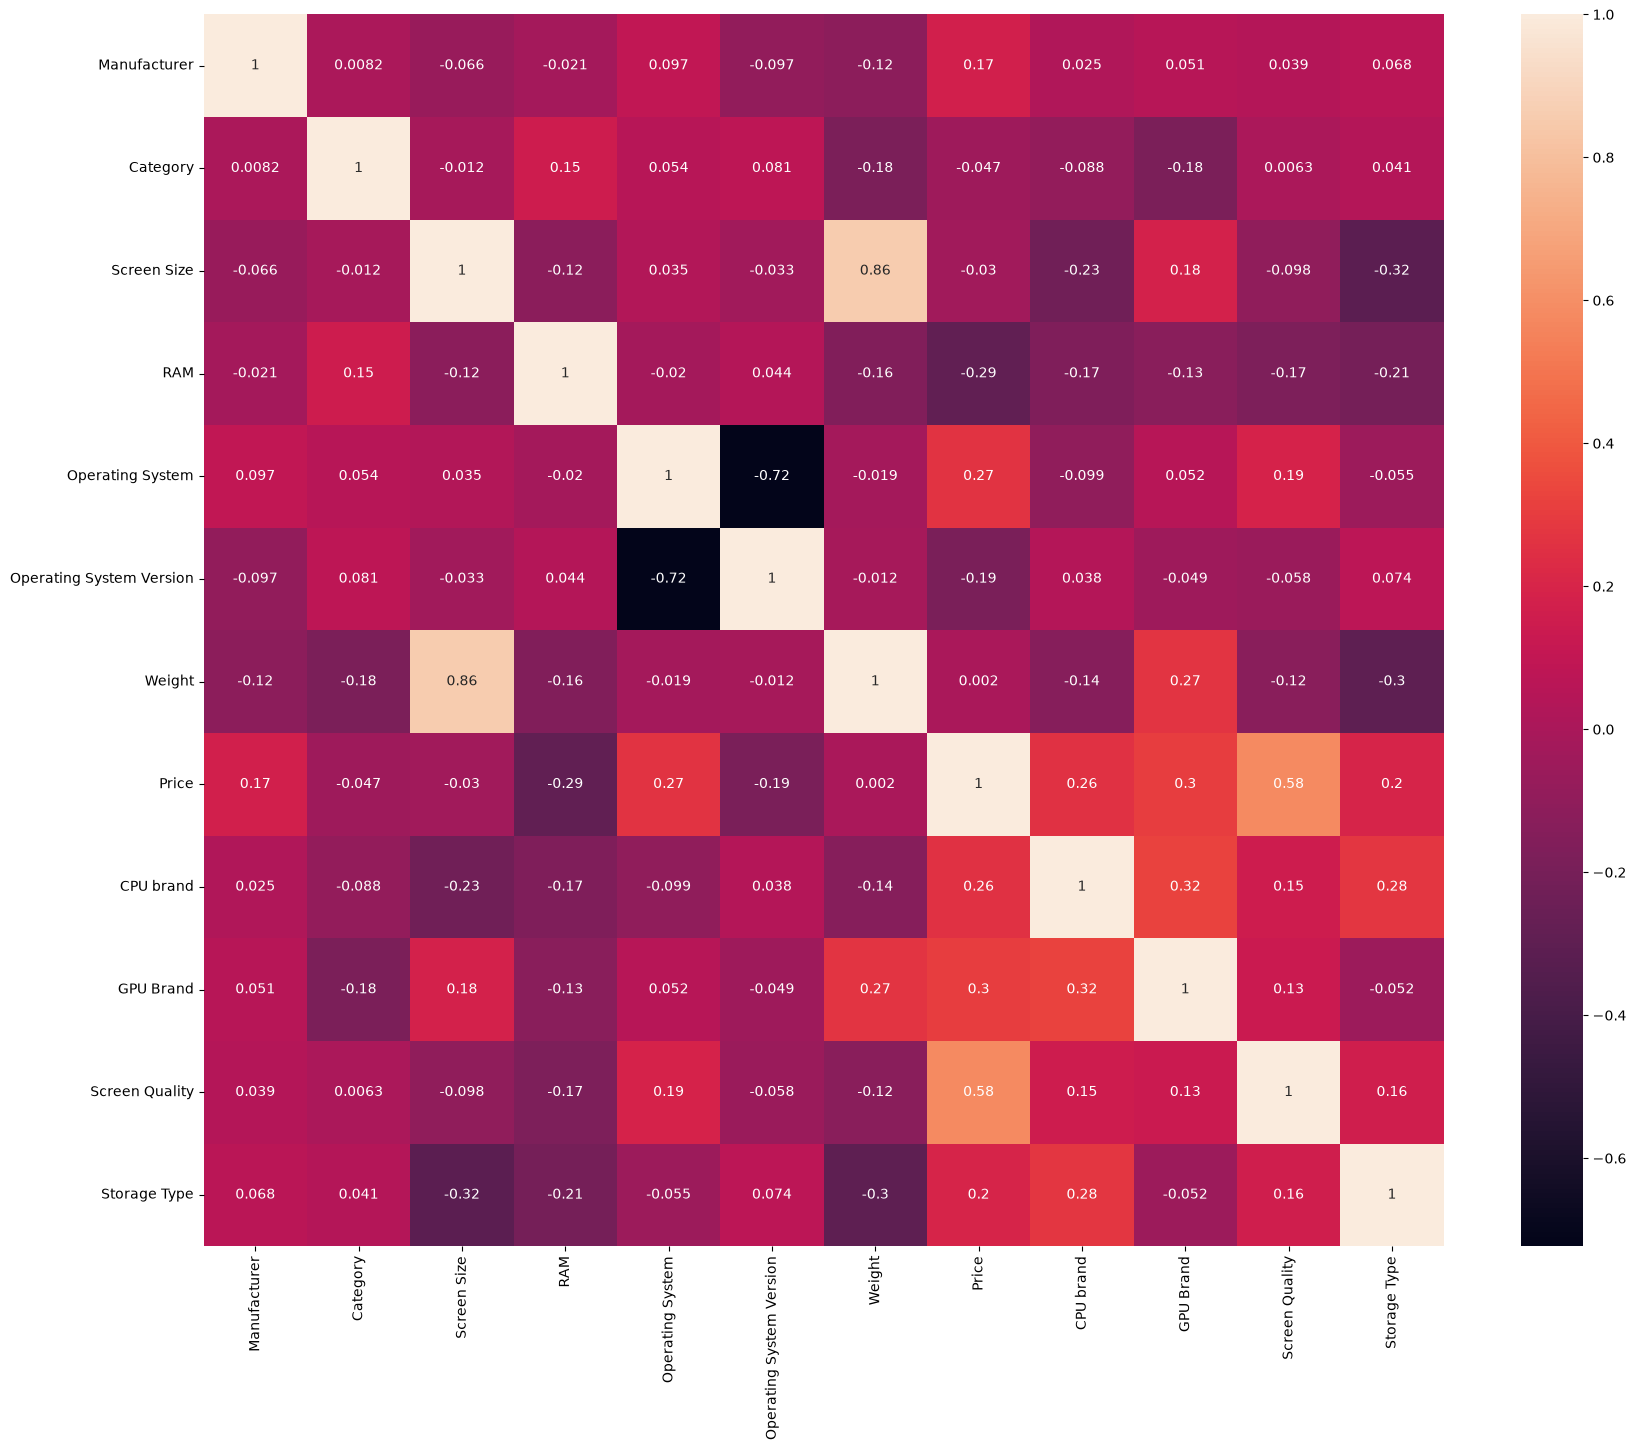

In [34]:
#Correlation Heatmap
plt.figure(figsize=(20, 16))
sns.heatmap(df_clean.corr(), fmt='.2g', annot=True)

# Machine Learning Model Building

In [35]:
# define x and y


x= df_clean.drop('Price',axis=1)
y=df_clean['Price']

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2, random_state=0)

# Decision Tree Regressor

In [37]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

In [38]:
# Create a DecisionTreeRegressor
import time
start_time = time.time()
dtree=DecisionTreeRegressor()


param_grid={
    'max_depth': [2, 4, 6, 8],
    'min_samples_split': [2, 4, 6, 8],
    'min_samples_leaf': [1, 2, 3, 4],
    'max_features': ['auto', 'sqrt', 'log2']}


# Create a GridSearchCV object
grid_search = GridSearchCV(dtree, param_grid, cv=5, scoring='neg_mean_squared_error')

# Fit the GridSearchCV object to the data
grid_search.fit(x_train, y_train)

#End time

end_time=time.time()

# Print the best hyperparameters
print(grid_search.best_params_)

{'max_depth': 6, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 8}


In [39]:
from sklearn.tree import DecisionTreeRegressor
dtree = DecisionTreeRegressor(random_state=0, max_depth=8, max_features='sqrt', min_samples_leaf=3, min_samples_split=4)
dtree.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",8
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",4
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",'sqrt'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with `

In [40]:
from sklearn import metrics
import math
y_pred = dtree.predict(x_test)
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)
r2 = metrics.r2_score(y_test, y_pred)
rmse = math.sqrt(mse)

print('MAE is {}'.format(mae))
print('MSE is {}'.format(mse))
print('R2 score is {}'.format(r2))
print('RMSE score is {}'.format(rmse))

MAE is 2444689.3141490687
MSE is 20123812945266.836
R2 score is 0.40192836067995164
RMSE score is 4485957.305332591


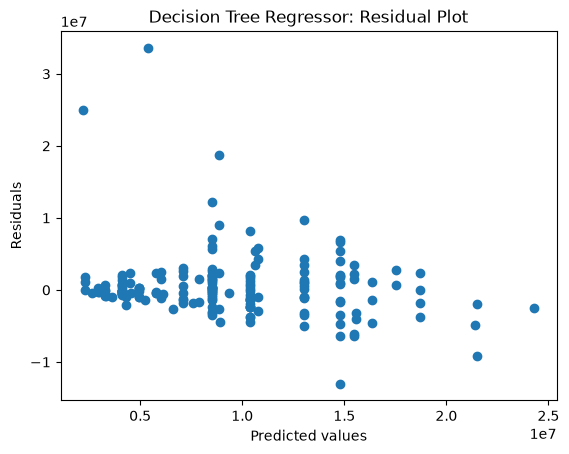

In [41]:
residuals = y_test - y_pred

# Create a scatter plot of predicted values vs residuals
plt.scatter(y_pred, residuals)
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.title("Decision Tree Regressor: Residual Plot")
plt.show()

# Random Forest Regressor

In [42]:
from sklearn.ensemble import RandomForestRegressor

In [43]:
Rtree=RandomForestRegressor()

param_grid={
   'n_estimators': [50, 100, 150, 200],
    'max_depth': [3, 5, 7, 9],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto', 'sqrt']}

In [44]:
# Create a GridSearchCV object
grid_search = GridSearchCV(Rtree, param_grid, cv=5, scoring='r2')

In [45]:
Rtree = RandomForestRegressor(random_state=0, max_depth=9, min_samples_split=2, min_samples_leaf=1, 
                           max_features='sqrt', n_estimators=50)
Rtree.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",9
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

In [46]:
from sklearn import metrics
import math
y_pred = Rtree.predict(x_test)
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)
r2 = metrics.r2_score(y_test, y_pred)
rmse = math.sqrt(mse)

print('MAE is {}'.format(mae))
print('MSE is {}'.format(mse))
print('R2 score is {}'.format(r2))
print('RMSE score is {}'.format(rmse))

MAE is 1802564.6793119463
MSE is 8447679949923.931
R2 score is 0.7489383443463966
RMSE score is 2906489.282609508


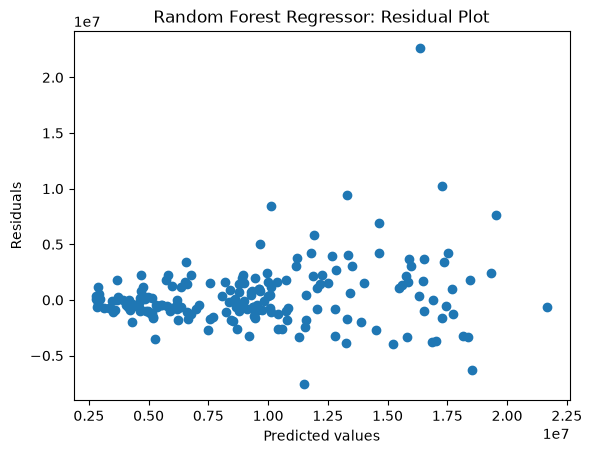

In [47]:
residuals = y_test - y_pred

# Create a scatter plot of predicted values vs residuals
plt.scatter(y_pred, residuals)
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.title("Random Forest Regressor: Residual Plot")
plt.show()

# Feature Importances

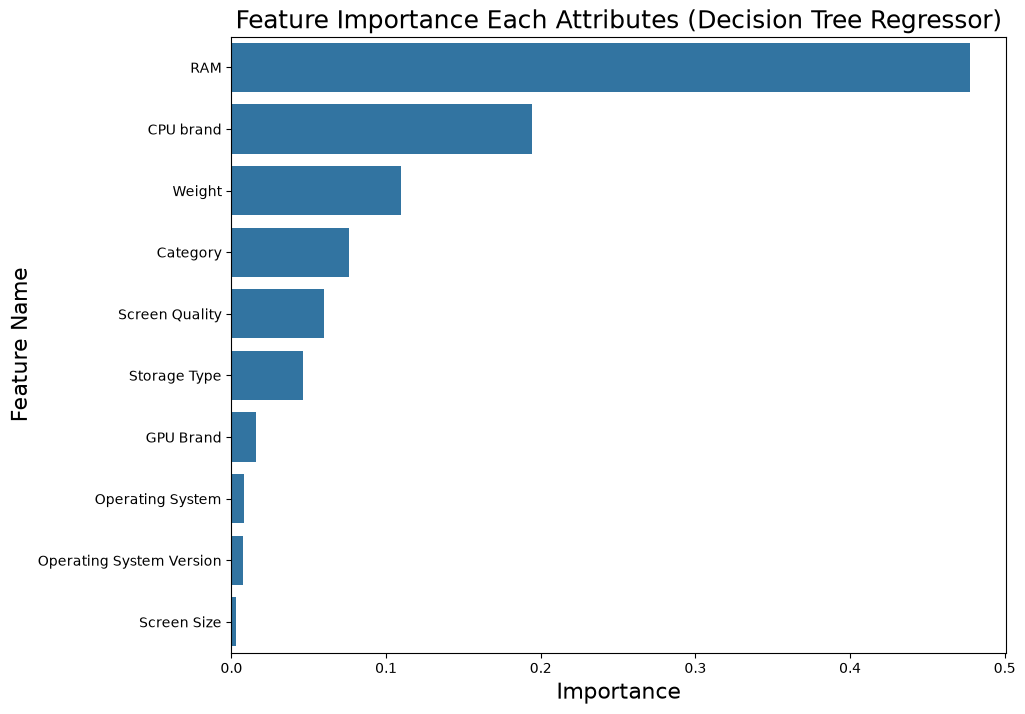

In [48]:
imp_df = pd.DataFrame({
    "Feature Name": x_train.columns,
    "Importance": dtree.feature_importances_
})
fi = imp_df.sort_values(by="Importance", ascending=False)

fi2 = fi.head(10)
plt.figure(figsize=(10,8))
sns.barplot(data=fi2, x='Importance', y='Feature Name')
plt.title('Feature Importance Each Attributes (Decision Tree Regressor)', fontsize=18)
plt.xlabel ('Importance', fontsize=16)
plt.ylabel ('Feature Name', fontsize=16)
plt.show()

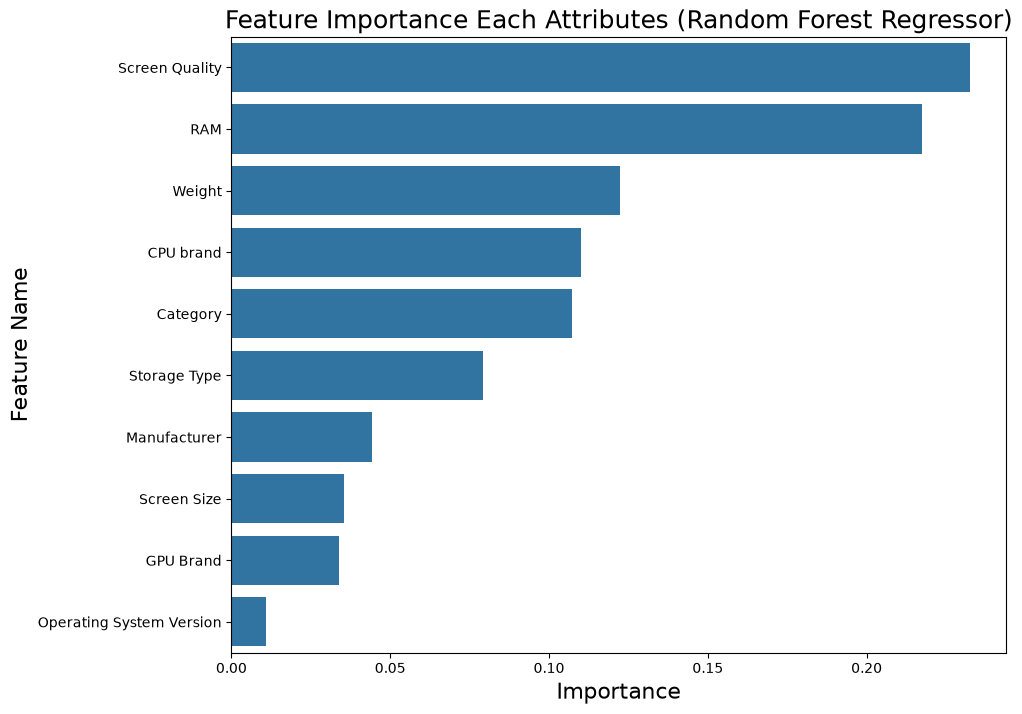

In [49]:
imp_df = pd.DataFrame({
    "Feature Name": x_train.columns,
    "Importance": Rtree.feature_importances_
})
fi = imp_df.sort_values(by="Importance", ascending=False)

fi2 = fi.head(10)
plt.figure(figsize=(10,8))
sns.barplot(data=fi2, x='Importance', y='Feature Name')
plt.title('Feature Importance Each Attributes (Random Forest Regressor)', fontsize=18)
plt.xlabel ('Importance', fontsize=16)
plt.ylabel ('Feature Name', fontsize=16)
plt.show()

# Apply to test data

In [50]:
df_test.head()

,Manufacturer,Model Name,Category,Screen Size,Screen,CPU,RAM,Storage,GPU,Operating System,Operating System Version,Weight,Price
0,HP,15-bs053od (i7-7500U/6GB/1TB/W10),Notebook,"15.6""",1366x768,Intel Core i7 7500U 2.7GHz,6GB,1TB HDD,Intel HD Graphics 620,Windows,10,2.04kg,5148468.0
1,Asus,Rog GL753VE-DS74,Gaming,"17.3""",Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1050 Ti,Windows,10,2.99kg,15552108.0
2,Dell,Inspiron 7579,2 in 1 Convertible,"15.6""",IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 7500U 2.7GHz,12GB,512GB SSD,Intel HD Graphics 620,Windows,10,2.19kg,11550708.0
3,Toshiba,Portege Z30-C-1CV,Notebook,"13.3""",Full HD 1920x1080,Intel Core i5 6200U 2.3GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows,7,1.2kg,10625940.0
4,Lenovo,IdeaPad 320-15ABR,Notebook,"15.6""",Full HD 1920x1080,AMD A12-Series 9720P 3.6GHz,6GB,256GB SSD,AMD Radeon 530,Windows,10,2.2kg,4881708.0


In [51]:
df_test['Weight'] = df_test['Weight'].str.strip('kg')
df_test['Screen Size'] = df_test['Screen Size'].str.strip('"')
df_test.head()

,Manufacturer,Model Name,Category,Screen Size,Screen,CPU,RAM,Storage,GPU,Operating System,Operating System Version,Weight,Price
0,HP,15-bs053od (i7-7500U/6GB/1TB/W10),Notebook,15.6,1366x768,Intel Core i7 7500U 2.7GHz,6GB,1TB HDD,Intel HD Graphics 620,Windows,10,2.04,5148468.0
1,Asus,Rog GL753VE-DS74,Gaming,17.3,Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1050 Ti,Windows,10,2.99,15552108.0
2,Dell,Inspiron 7579,2 in 1 Convertible,15.6,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 7500U 2.7GHz,12GB,512GB SSD,Intel HD Graphics 620,Windows,10,2.19,11550708.0
3,Toshiba,Portege Z30-C-1CV,Notebook,13.3,Full HD 1920x1080,Intel Core i5 6200U 2.3GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows,7,1.2,10625940.0
4,Lenovo,IdeaPad 320-15ABR,Notebook,15.6,Full HD 1920x1080,AMD A12-Series 9720P 3.6GHz,6GB,256GB SSD,AMD Radeon 530,Windows,10,2.2,4881708.0


In [52]:
df_test['CPU brand'] = df_test['CPU'].apply(fetch_processor)

<Axes: xlabel='CPU brand'>

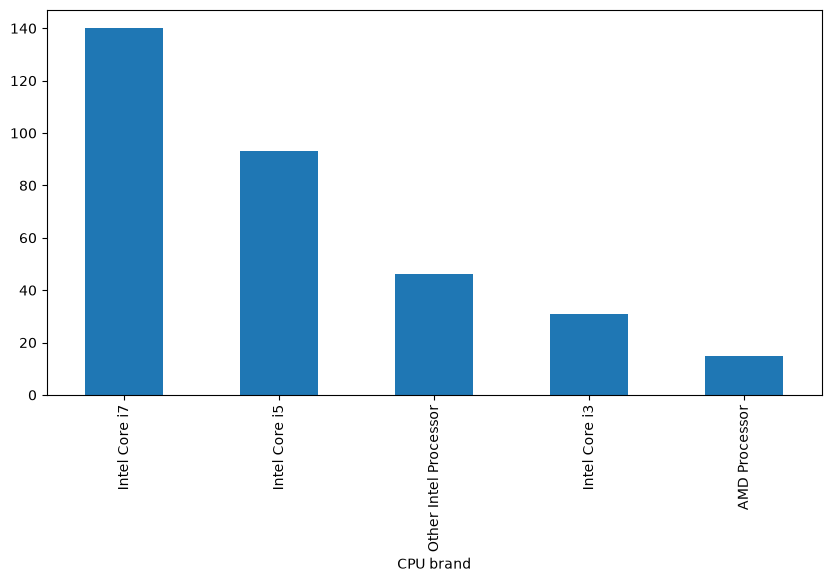

In [53]:
plt.figure(figsize=(10,5))
df_test['CPU brand'].value_counts().plot(kind='bar')

In [54]:
df_test['GPU Brand'] = df_test['GPU'].apply(gpu_type)

<Axes: xlabel='GPU Brand'>

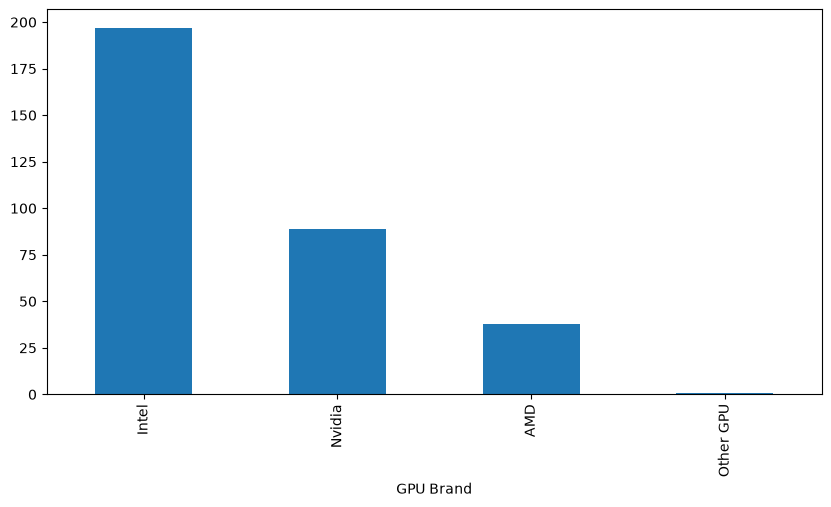

In [55]:
plt.figure(figsize=(10,5))
df_test['GPU Brand'].value_counts().plot(kind='bar')

In [56]:
df_test['Operating System'] = df_test['Operating System'].replace('Mac OS', 'macOS')

In [57]:
df_test['Screen Quality'] = df_test['Screen'].str.slice(-9)

<Axes: xlabel='Screen Quality'>

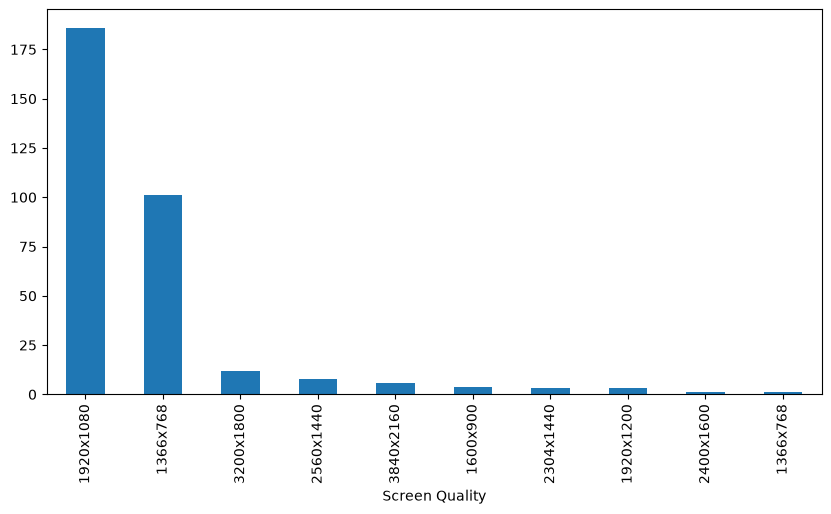

In [58]:
plt.figure(figsize=(10,5))
df_test['Screen Quality'].value_counts().plot(kind='bar')

In [59]:
df_test['Storage Type'] = df_test[' Storage'].apply(fetch_storage)

<Axes: xlabel='Storage Type'>

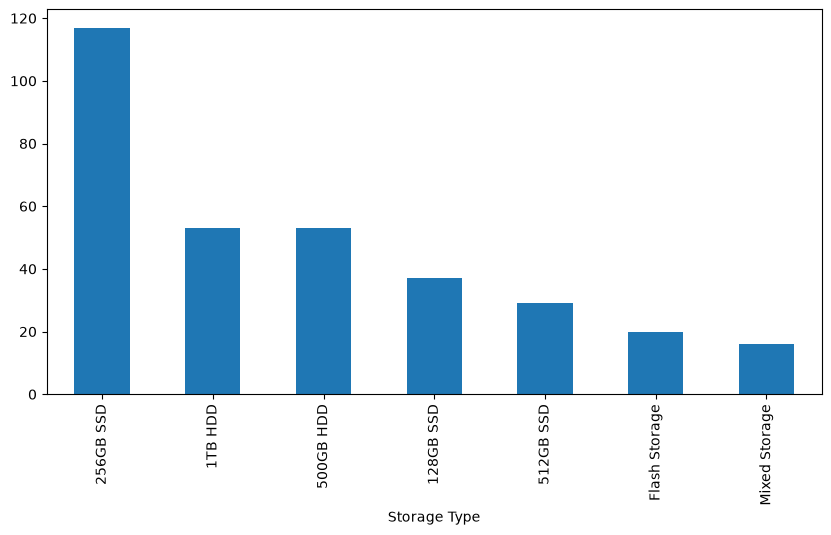

In [60]:
plt.figure(figsize=(10,5))
df_test['Storage Type'].value_counts().plot(kind='bar')

In [61]:
df_test.drop(columns=['Model Name', 'Screen', 'CPU', ' Storage', 'GPU', 'Price'], inplace=True)
df_test.shape

(325, 11)

In [62]:
df_test.head()

,Manufacturer,Category,Screen Size,RAM,Operating System,Operating System Version,Weight,CPU brand,GPU Brand,Screen Quality,Storage Type
0,HP,Notebook,15.6,6GB,Windows,10,2.04,Intel Core i7,Intel,1366x768,1TB HDD
1,Asus,Gaming,17.3,16GB,Windows,10,2.99,Intel Core i7,Nvidia,1920x1080,256GB SSD
2,Dell,2 in 1 Convertible,15.6,12GB,Windows,10,2.19,Intel Core i7,Intel,1920x1080,512GB SSD
3,Toshiba,Notebook,13.3,4GB,Windows,7,1.2,Intel Core i5,Intel,1920x1080,128GB SSD
4,Lenovo,Notebook,15.6,6GB,Windows,10,2.2,AMD Processor,AMD,1920x1080,256GB SSD


In [63]:
check_missing = df_test.isnull().sum() * 100 / df_test.shape[0]
check_missing[check_missing > 0].sort_values(ascending=False)

Operating System Version    10.461538
dtype: float64

In [64]:
df_test.fillna('Unknown', inplace=True)
df_test.head()

,Manufacturer,Category,Screen Size,RAM,Operating System,Operating System Version,Weight,CPU brand,GPU Brand,Screen Quality,Storage Type
0,HP,Notebook,15.6,6GB,Windows,10,2.04,Intel Core i7,Intel,1366x768,1TB HDD
1,Asus,Gaming,17.3,16GB,Windows,10,2.99,Intel Core i7,Nvidia,1920x1080,256GB SSD
2,Dell,2 in 1 Convertible,15.6,12GB,Windows,10,2.19,Intel Core i7,Intel,1920x1080,512GB SSD
3,Toshiba,Notebook,13.3,4GB,Windows,7,1.2,Intel Core i5,Intel,1920x1080,128GB SSD
4,Lenovo,Notebook,15.6,6GB,Windows,10,2.2,AMD Processor,AMD,1920x1080,256GB SSD


In [65]:
# Loop over each column in the DataFrame where dtype is 'object'
for col in df_test.select_dtypes(include=['object']).columns:
    
    # Print the column name and the unique values
    print(f"{col}: {df_test[col].unique()}")

Manufacturer: ['HP' 'Asus' 'Dell' 'Toshiba' 'Lenovo' 'Fujitsu' 'Acer' 'MSI' 'Vero'
 'Apple' 'Razer' 'Samsung']
Category: ['Notebook' 'Gaming' '2 in 1 Convertible' 'Netbook' 'Ultrabook'
 'Workstation']
Screen Size: ['15.6' '17.3' '13.3' '14.0' '12.5' '11.6' '12.0' '10.1' '12.3' '15.0']
RAM: ['6GB' '16GB' '12GB' '4GB' '8GB' '2GB' '64GB' '32GB']
Operating System: ['Windows' 'No OS' 'Chrome OS' 'macOS' 'Linux' 'Android']
Operating System Version: ['10' '7' 'Unknown' 'X']
Weight: ['2.04' '2.99' '2.19' '1.2' '2.2' '2.3' '1.75' '2.25' '2.5' '2.36' '1.6'
 '0.97' '2.1' '1.9' '1.68' '1.4' '1.11' '2.4' '1.48' '2.7' '1.34' '2.18'
 '1.64' '1.95' '1.43' '2.65' '1.26' '1.54' '1.49' '1.5' '1.47' '2.08'
 '2.09' '2.31' '1.29' '2.63' '1.84' '1.8' '1.45' '3.78' '4.6' '1.1' '1.91'
 '1.96' '2.94' '4kgs' '2.32' '3.58' '1.62' '3.21' '0.920' '2.06' '1.3'
 '3.0' '0.99' '0.69' '1.7' '1.86' '2.6' '4.3' '2.20' '2.9' '2.59' '1.16'
 '2.24' '1.23' '1.25' '1.05' '3.52' '1.35' '2' '3.35' '2.23' '3' '1.88'
 '2.8' '2.0' 

In [66]:
from sklearn import preprocessing

# Loop over each column in the DataFrame where dtype is 'object'
for col in df_test.select_dtypes(include=['object']).columns:
    
    # Initialize a LabelEncoder object
    label_encoder = preprocessing.LabelEncoder()
    
    # Fit the encoder to the unique values in the column
    label_encoder.fit(df_test[col].unique())
    
    # Transform the column using the encoder
    df_test[col] = label_encoder.transform(df_test[col])
    
    # Print the column name and the unique encoded values
    print(f"{col}: {df_test[col].unique()}")

Manufacturer: [ 5  2  3 10  6  4  0  7 11  1  8  9]
Category: [3 1 0 2 4 5]
Screen Size: [8 9 5 6 4 1 2 0 3 7]
RAM: [6 1 0 4 7 2 5 3]
Operating System: [4 3 1 5 2 0]
Operating System Version: [0 1 2 3]
Weight: [48 83 55 11 57 64 36 62 71 68 31  2 53 41 34 22  7 69 27 78 19 54 33 43
 23 77 15 30 28 29 26 51 52 65 17 76 38 37 25 92 96  6 42 44 82 97 66 91
 32 86  1 49 18 85  3  0 35 39 74 95 58 81 72  9 61 12 14  4 90 20 46 89
 60 84 40 80 47 16 75 24 88 50 21 45 73 94  8 59 70 87 56  5 79 67 13 93
 63 10]
CPU brand: [3 2 0 4 1]
GPU Brand: [1 2 0 3]
Screen Quality: [1 3 8 9 7 5 2 4 6 0]
Storage Type: [1 2 4 0 3 6 5]


# Price Prediction on Test Data

In [68]:
pd.set_option('display.float_format', '{:.0f}'.format)
y_pred_prob = Rtree.predict(df_test)
y_pred_prob_df = pd.DataFrame(data=y_pred_prob)
y_pred_prob_df

,0
0,10062766
1,17976149
2,15347868
3,11151955
4,8747916
...,...
320,12811994
321,22606980
322,10426605
323,10059947
